# End to end: encode, decode, and 1000 trials

One code, the complete chain, and then a thousand randomized runs of it.

The other notebooks each take one stage apart. This one wires all of them together and
then hammers it, so the claims stop being "it worked on the example I picked".

| Stage | Forward | Backward |
|---|---|---|
| 1 | message $\to$ hypervector | hypervector $\to$ message |
| 2 | atoms $\to$ **bind** $\to$ object | object $\to$ attributes |
| 3 | objects $\to$ **bundle** $\to$ scene | scene $\to$ the set of objects |

Stages 1 and 2 are exact and cheap: binding never leaves the codeword set, so going
backwards is a decode. Stage 3 is the hard one --- a bundle is not a codeword, so it
needs §IV-A to get histograms and §IV-B to turn those back into codewords.

The code is $p = 3$, $m = 3$, $K = 3$: nothing degenerate, $N = 27$, hypervectors of
dimension $729$, and $19{,}683$ nameable messages.

In [1]:
import itertools
import random
import time

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

import sage.all__sagemath_modules as _sage_bootstrap   # must precede sage.coding
from sage.coding.grs_code import GeneralizedReedSolomonCode
from sage.coding.guruswami_sudan.gs_decoder import GRSGuruswamiSudanDecoder
from sage.coding.guruswami_sudan.interpolation import gs_interpolation_linalg
from sage.rings.finite_rings.finite_field_constructor import GF

%matplotlib inline
np.set_printoptions(precision=3, suppress=True, linewidth=130)


def load_notebook_defs(path):
    """exec another notebook's code cells, skipping figures and magics."""
    import ast, contextlib, io, json

    def draws(src):
        try:
            tree = ast.parse(src)
        except SyntaxError:
            return False
        return any(isinstance(n, ast.Call) and isinstance(n.func, ast.Attribute)
                   and n.func.attr in ("show", "savefig") for n in ast.walk(tree))

    nb = json.loads(open(path).read())
    ns = {}
    for cell in nb["cells"]:
        if cell["cell_type"] != "code":
            continue
        src = "".join(cell["source"])
        if draws(src):
            continue
        src = "\n".join(("# " + ln) if ln.lstrip()[:1] in ("%", "!") else ln
                        for ln in src.split("\n"))
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                exec(compile(src, path, "exec"), ns)
        except Exception:
            pass
    return ns


enc = load_notebook_defs("encode_m.ipynb")          # the encoder, 0.7 s to load

p, m, K = 3, 3, 3
q = N = p ** m
DIM = p ** (2 * m)
tab = enc["gf_tables"](p, m)

F = GF(q, "a", modulus=enc["find_irreducible"](p, m))
gen = F.gen()
to_sage = lambda i: sum(int(c) * gen ** k for k, c in enumerate(tab[0][i]))
points = [to_sage(j) for j in range(N)]             # our integer order
FROM_SAGE = {points[i]: i for i in range(N)}
CODE = GeneralizedReedSolomonCode(points, K)
ROOT_FINDER = GRSGuruswamiSudanDecoder(
    CODE, tau=1, interpolation_alg="LinearAlgebra").rootfinding_algorithm()

d_min = N - K + 1
mu = (K - 1) / N
l_max = (2 * N - d_min) / (2 * (N - d_min))
u_max = (N - 1) // (K - 1)

print(f"p = {p}, m = {m}, K = {K}")
print(f"  N = p^m          = {N}        Reed-Solomon block length")
print(f"  dim = p^2m       = {DIM}      hypervector length")
print(f"  size = N^K       = {N ** K}    nameable messages")
print(f"  d_min = N-K+1    = {d_min}")
print(f"  mu = (K-1)/N     = {mu:.4f}")
print(f"  l_max            = {l_max:.2f}     inner product can DETECT this many")
print(f"  u_max            = {u_max}        IV-B can RECONSTRUCT this many")
assert CODE.minimum_distance() == d_min

p = 3, m = 3, K = 3
  N = p^m          = 27        Reed-Solomon block length
  dim = p^2m       = 729      hypervector length
  size = N^K       = 19683    nameable messages
  d_min = N-K+1    = 25
  mu = (K-1)/N     = 0.0741
  l_max            = 7.25     inner product can DETECT this many
  u_max            = 13        IV-B can RECONSTRUCT this many


## Stage 1 --- a message there and back

Forward is the paper's eq. (1): Reed--Solomon, then Hadamard, then $\phi$.

Backward exploits $H^\dagger H = N I$. Each block of $N$ entries is one Hadamard column,
so $\frac{1}{N}H^\dagger$ applied block-wise gives a one-hot vector per position, and
`argmax` reads off the symbol. That recovers the codeword; Sage's `unencode` then solves
the Vandermonde system for the message.

One function serves both here and in stage 3: `histograms` returns *counts* of symbols per
position. For a single codeword every count is 0 or 1, so `argmax` is a decode. For a
bundle of $t$ they are genuine histograms summing to $t$.

In [2]:
def encode_message(u):
    """message (K symbols of F_{p^m})  ->  hypervector in C^{p^2m}."""
    return enc["histo_encode"](list(u), p, m, tab)


def histograms(vec):
    """Section IV-A. h_j = (1/N) H^dagger v_j, block by block.

    Entry (a, j) counts how many superimposed codewords carry symbol a at
    position j. For a single codeword that is a one-hot indicator.
    """
    H = enc["hadamard_matrix"](p, m, tab)
    blocks = np.asarray(vec).reshape(N, N).T
    return np.rint((H.conj().T @ blocks).real / N).astype(int)


def decode_hypervector(hv):
    """hypervector  ->  the RS codeword it encodes (exact, noiseless)."""
    return list(histograms(hv).argmax(axis=0))


def message_of_codeword(cw):
    """RS codeword  ->  message. Sage's unencode solves x . G = c."""
    c = CODE.ambient_space()([points[a] for a in cw])
    return [FROM_SAGE[x] for x in CODE.unencode(c)]


rng = random.Random(0)
u = [rng.randrange(q) for _ in range(K)]
hv = encode_message(u)
cw = decode_hypervector(hv)
back = message_of_codeword(cw)

print(f"message   u = {u}")
print(f"  -> RS codeword  {cw}")
print(f"  -> hypervector  dim {hv.shape[0]}, |entry| = 1 everywhere: "
      f"{np.allclose(np.abs(hv), 1.0)}, norm {np.linalg.norm(hv):.1f} = sqrt(dim)")
print(f"  <- decoded codeword {cw}   matches: {cw == list(enc['reed_solomon_encode'](u, p, m, tab))}")
print(f"  <- recovered message {back}")
assert back == u
print(f"\nround trip exact: {back == u}")

message   u = [12, 24, 13]
  -> RS codeword  [12, 13, 1, 20, 7, 2, 0, 21, 5, 24, 18, 11, 11, 18, 24, 6, 23, 6, 2, 7, 20, 1, 13, 12, 5, 21, 0]
  -> hypervector  dim 729, |entry| = 1 everywhere: True, norm 27.0 = sqrt(dim)
  <- decoded codeword [12, 13, 1, 20, 7, 2, 0, 21, 5, 24, 18, 11, 11, 18, 24, 6, 23, 6, 2, 7, 20, 1, 13, 12, 5, 21, 0]   matches: True
  <- recovered message [12, 24, 13]

round trip exact: True


## Stage 2 --- bind, and take it apart again

Three attributes, each owning one of the $K = 3$ message coordinates. That is the
"trivially intersecting subcodes" construction, and the disjointness is what makes
unbinding unique (`linear.pdf`, Remark 7).

Binding is **multiply entry by entry**. Because the $p$-th roots of unity are closed
under multiplication, the product is still a codeword --- so unbinding is just stage 1's
decode followed by reading off the three slots.

In [3]:
ATTRIBUTES = {
    "colour": ["red", "green", "blue", "yellow"],
    "shape":  ["circle", "square", "triangle", "hexagon"],
    "size":   ["tiny", "small", "large", "huge"],
}
SLOT = {name: i for i, name in enumerate(ATTRIBUTES)}          # attribute -> coordinate
CODE_OF = {(a, v): j + 1 for a, vs in ATTRIBUTES.items() for j, v in enumerate(vs)}
VALUE_OF = {(a, c): v for (a, v), c in CODE_OF.items()}


def atom(attribute, value):
    """One attribute-value pair: its code in that attribute's slot, zero elsewhere."""
    u = [0] * K
    u[SLOT[attribute]] = CODE_OF[(attribute, value)]
    return encode_message(u)


def bind(*hypervectors):
    """Bind = multiply entry by entry."""
    out = hypervectors[0].copy()
    for hvec in hypervectors[1:]:
        out = out * hvec
    return out


def encode_object(obj):
    return bind(*[atom(a, obj[a]) for a in ATTRIBUTES])


def read_attributes(message):
    """message -> the attribute values, by reading each attribute's own slot."""
    return {a: VALUE_OF[(a, message[SLOT[a]])] for a in ATTRIBUTES}


obj = {"colour": "green", "shape": "triangle", "size": "large"}
bound = encode_object(obj)
recovered = read_attributes(message_of_codeword(decode_hypervector(bound)))

print(f"object {obj}")
print(f"  bound hypervector: dim {bound.shape[0]}, still |entry| = 1: "
      f"{np.allclose(np.abs(bound), 1.0)}  <- binding stays in the code")
print(f"  recovered {recovered}")
assert recovered == obj

# the product really is the encoding of the field sum of the atom messages
vec_, ADD_, MUL_ = tab
msgs = [[0] * K for _ in ATTRIBUTES]
for a in ATTRIBUTES:
    msgs[SLOT[a]][SLOT[a]] = CODE_OF[(a, obj[a])]
summed = [int(ADD_[ADD_[x, y], z]) for x, y, z in zip(*msgs)]
assert np.allclose(bound, encode_message(summed))
print(f"  bind(atoms) == encode(field sum {summed}): True")

ALL_OBJECTS = [dict(zip(ATTRIBUTES, combo))
               for combo in itertools.product(*ATTRIBUTES.values())]
bad = [o for o in ALL_OBJECTS
       if read_attributes(message_of_codeword(decode_hypervector(encode_object(o)))) != o]
print(f"\nall {len(ALL_OBJECTS)} objects round-trip: {not bad}")

object {'colour': 'green', 'shape': 'triangle', 'size': 'large'}
  bound hypervector: dim 729, still |entry| = 1: True  <- binding stays in the code
  recovered {'colour': 'green', 'shape': 'triangle', 'size': 'large'}
  bind(atoms) == encode(field sum [2, 3, 3]): True

all 64 objects round-trip: True


## Stage 3 --- bundle, and recover the set

Bundling is **add entry by entry**. That leaves the codeword set --- the moduli stop
being 1 --- so there is nothing to decode. Recovery is two stages:

- **§IV-A** gives histograms, which is the same `histograms` call as stage 1.
- **§IV-B** (Sidorenko--Fischer Algorithm 2) turns them back into codewords: interpolate
  a curve through every (position, symbol) pair that appeared, factor out $y - f(x)$,
  then keep the candidates whose every symbol was observed.

In [4]:
def support_matrix(hist):
    """Y: which symbols appeared at each position, counts discarded."""
    return (hist > 0).astype(int)


def score(codeword, M):
    """<W(c), M> -- sum M over the one-hot positions of c."""
    return sum(int(M[int(a), j]) for j, a in enumerate(codeword))


def ks_algorithm_2(Y, d, agree=None, ell_max=40):
    """Sidorenko-Fischer Algorithm 2: interpolate, then factor. No filtering.

    Sage's degree bound is exclusive, so tau = n_P - agree caps the weighted
    degree at agree*d - 1, the largest the counting argument permits.
    """
    if agree is None:
        agree = N
    P = [(points[j], points[a]) for j in range(N) for a in range(N) if Y[a, j]]
    tau = len(P) - agree
    for ell in range(2, ell_max):
        try:
            Q = gs_interpolation_linalg(P, tau, (d, ell), K - 1)
        except (IndexError, ValueError):
            continue
        return list(ROOT_FINDER(Q, maxd=K - 1)), len(P), ell
    raise RuntimeError(f"no interpolation polynomial up to ell = {ell_max}")


def ks_list_decode(Y, d=1, agree=None, ell_max=40):
    """Algorithm 2, then this paper's rejection step: keep score >= d*agree."""
    if agree is None:
        agree = N
    cands, n_P, ell = ks_algorithm_2(Y, d, agree=agree, ell_max=ell_max)
    kept = [f for f in cands
            if score([FROM_SAGE[f(x)] for x in points], d * Y) >= d * agree]
    return kept, n_P, ell


def message_of_poly(f):
    """polynomial -> message, in our integer encoding."""
    zero = f.base_ring().zero()
    coeffs = list(f.list()) + [zero] * (K - len(f.list()))
    return [FROM_SAGE[c] for c in coeffs]


rng = random.Random(1)
scene = [ALL_OBJECTS[i] for i in rng.sample(range(len(ALL_OBJECTS)), 4)]
bundle = sum(encode_object(o) for o in scene)

print(f"bundled t = {len(scene)} objects:")
for o in scene:
    print(f"   {o}")
print(f"\nbundle: dim {bundle.shape[0]}, |entry| in "
      f"[{np.abs(bundle).min():.1f}, {np.abs(bundle).max():.1f}]"
      f"  <- not 1, so NOT a codeword")

hist = histograms(bundle)
print(f"column sums of the histograms = {list(hist.sum(axis=0))}  -> t = "
      f"{int(hist.sum(axis=0)[0])} read straight off the data")
Y = support_matrix(hist)
found, n_P, ell = ks_list_decode(Y, d=1)
got = [read_attributes(message_of_poly(f)) for f in found]

print(f"\nIV-B over n_P = {n_P} points, ell = {ell}: recovered {len(got)} object(s)")
key = lambda o: tuple(sorted(o.items()))
for o in sorted(got, key=key):
    print(f"   {o}")
assert sorted(got, key=key) == sorted(scene, key=key)
print(f"\nexactly the bundled set, nothing spurious: True")

bundled t = 4 objects:
   {'colour': 'green', 'shape': 'circle', 'size': 'small'}
   {'colour': 'red', 'shape': 'triangle', 'size': 'tiny'}
   {'colour': 'blue', 'shape': 'circle', 'size': 'tiny'}
   {'colour': 'red', 'shape': 'hexagon', 'size': 'huge'}

bundle: dim 729, |entry| in [1.0, 4.0]  <- not 1, so NOT a codeword
column sums of the histograms = [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]  -> t = 4 read straight off the data

IV-B over n_P = 99 points, ell = 4: recovered 4 object(s)
   {'colour': 'blue', 'shape': 'circle', 'size': 'tiny'}
   {'colour': 'green', 'shape': 'circle', 'size': 'small'}
   {'colour': 'red', 'shape': 'hexagon', 'size': 'huge'}
   {'colour': 'red', 'shape': 'triangle', 'size': 'tiny'}

exactly the bundled set, nothing spurious: True


## 1000 trials

Everything above used one seed. Now run the whole chain a thousand times on fresh random
data, with $t$ drawn uniformly from $1..4$, recording for each trial whether every stage
round-tripped and how long §IV-B took.

Stages 1 and 2 cost about $0.1$ ms; §IV-B dominates, from ~13 ms at $t=2$ to ~80 ms at
$t=4$, so expect roughly a minute.

In [5]:
TRIALS = 1000
T_CHOICES = [1, 2, 3, 4]
trial_rng = random.Random(20260930)

results = []
t_start = time.time()
for i in range(TRIALS):
    # --- stage 1: message round trip -------------------------------------------
    u = [trial_rng.randrange(q) for _ in range(K)]
    s1 = message_of_codeword(decode_hypervector(encode_message(u))) == u

    # --- stage 2: bind and unbind ----------------------------------------------
    obj = {a: trial_rng.choice(vs) for a, vs in ATTRIBUTES.items()}
    s2 = read_attributes(message_of_codeword(decode_hypervector(
        encode_object(obj)))) == obj

    # --- stage 3: bundle and recover the set -----------------------------------
    t = trial_rng.choice(T_CHOICES)
    scene = [ALL_OBJECTS[j]
             for j in trial_rng.sample(range(len(ALL_OBJECTS)), t)]
    bundle = sum(encode_object(o) for o in scene)
    hist = histograms(bundle)
    iva = int(hist.sum(axis=0)[0]) == t and (hist.sum(axis=0) == t).all()
    Y = support_matrix(hist)
    t0 = time.time()
    try:
        found, n_P, ell = ks_list_decode(Y, d=1)
        got = sorted((read_attributes(message_of_poly(f)) for f in found), key=key)
        s3 = got == sorted(scene, key=key)
        n_list = len(found)
    except RuntimeError:
        s3, n_list, n_P, ell = False, 0, int(Y.sum()), -1
    ms = (time.time() - t0) * 1000

    results.append(dict(t=t, stage1=s1, stage2=s2, iva=iva, stage3=s3,
                        n_list=n_list, n_P=n_P, ell=ell, ms=ms, wtY=int(Y.sum())))
    if (i + 1) % 200 == 0:
        ok = sum(r["stage1"] and r["stage2"] and r["iva"] and r["stage3"]
                 for r in results)
        print(f"  {i + 1:>4} trials, {ok} fully correct, "
              f"{time.time() - t_start:>5.1f}s elapsed")

elapsed = time.time() - t_start
print(f"\n{TRIALS} trials in {elapsed:.1f}s ({elapsed / TRIALS * 1000:.1f} ms each)")

   200 trials, 200 fully correct,   7.4s elapsed


   400 trials, 400 fully correct,  14.3s elapsed


   600 trials, 600 fully correct,  21.0s elapsed


   800 trials, 800 fully correct,  29.2s elapsed


  1000 trials, 1000 fully correct,  37.4s elapsed

1000 trials in 37.4s (37.4 ms each)


In [6]:
def pct(rows, field):
    return 100.0 * sum(r[field] for r in rows) / len(rows) if rows else float("nan")


print(f"{'stage':<34} {'correct':>9}")
print("-" * 45)
print(f"{'1  message -> hv -> message':<34} {pct(results, 'stage1'):>8.1f}%")
print(f"{'2  bind -> unbind':<34} {pct(results, 'stage2'):>8.1f}%")
print(f"{'3a IV-A histograms exact':<34} {pct(results, 'iva'):>8.1f}%")
print(f"{'3b IV-B recovered the set':<34} {pct(results, 'stage3'):>8.1f}%")
allok = [r for r in results if r["stage1"] and r["stage2"] and r["iva"] and r["stage3"]]
print(f"{'all four':<34} {100.0 * len(allok) / len(results):>8.1f}%")

print(f"\nbroken down by t   (u_max = {u_max}, l_max = {l_max:.2f})")
print(f"{'t':>3} {'trials':>7} {'IV-B ok':>9} {'mean list':>10} {'mean n_P':>9} "
      f"{'median ms':>10} {'wt(Y)':>7} {'worst t*N':>10}")
print("-" * 72)
for t in T_CHOICES:
    rows = [r for r in results if r["t"] == t]
    print(f"{t:>3} {len(rows):>7} {pct(rows, 'stage3'):>8.1f}% "
          f"{np.mean([r['n_list'] for r in rows]):>10.2f} "
          f"{np.mean([r['n_P'] for r in rows]):>9.1f} "
          f"{np.median([r['ms'] for r in rows]):>10.1f} "
          f"{np.mean([r['wtY'] for r in rows]):>7.1f} {t * N:>10}")

assert pct(results, "stage1") == 100.0, "stage 1 must never fail"
assert pct(results, "stage2") == 100.0, "stage 2 must never fail"
assert pct(results, "iva") == 100.0, "IV-A is exact when noiseless"
assert pct(results, "stage3") == 100.0, "IV-B must recover every t <= u_max"
# the stronger claim: the list is not merely short and correct, it is exactly the
# bundled set. No spurious candidate survived the rejection step in any trial.
assert all(r["n_list"] == r["t"] for r in results), "list size must equal t"
print(f"and the returned list was exactly t in all {len(results)} trials, "
      f"never longer.")
print("\nall four stages: 1000/1000. Asserted.")

stage                                correct
---------------------------------------------
1  message -> hv -> message           100.0%
2  bind -> unbind                     100.0%
3a IV-A histograms exact              100.0%
3b IV-B recovered the set             100.0%
all four                              100.0%

broken down by t   (u_max = 13, l_max = 7.25)
  t  trials   IV-B ok  mean list  mean n_P  median ms   wt(Y)  worst t*N
------------------------------------------------------------------------
  1     253    100.0%       1.00      27.0        9.6    27.0         27
  2     242    100.0%       2.00      52.9       14.0    52.9         54
  3     265    100.0%       3.00      77.6       39.2    77.6         81
  4     240    100.0%       4.00     101.5       83.1   101.5        108
and the returned list was exactly t in all 1000 trials, never longer.

all four stages: 1000/1000. Asserted.


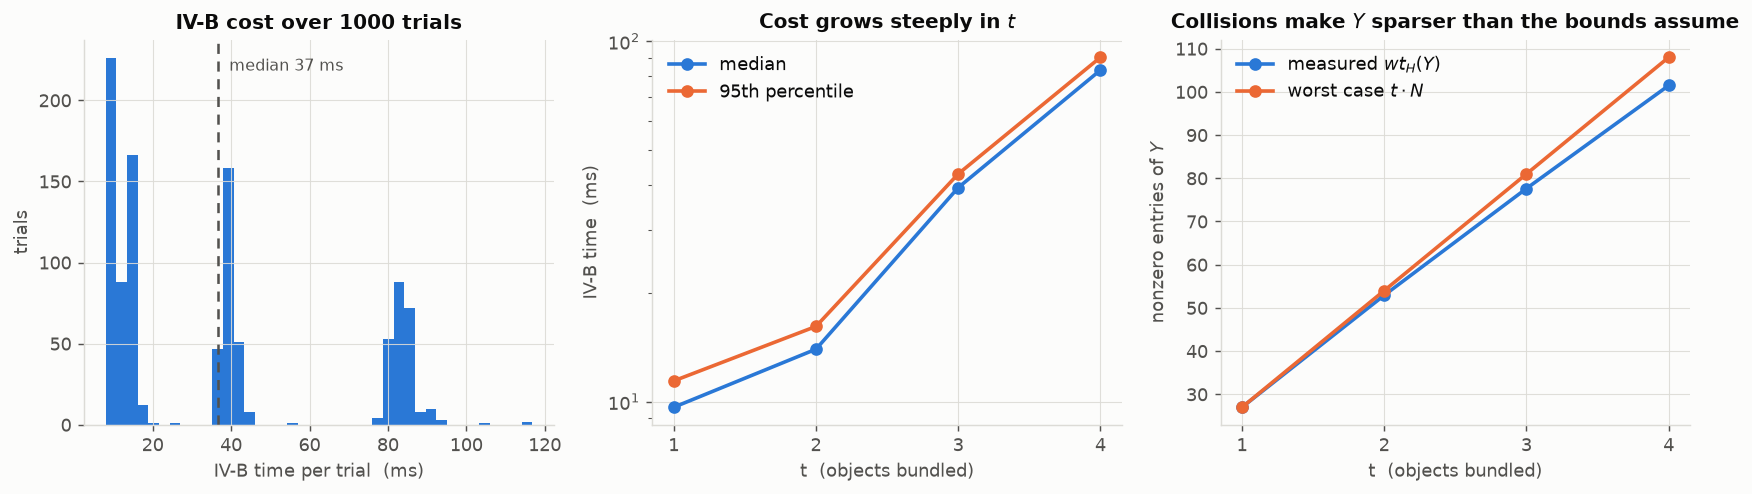

In [7]:
MODE = "light"
PALETTE = {
    "light": {"surface": "#fcfcfb", "ink": "#0b0b0b", "ink2": "#52514e",
              "grid": "#dcdbd6", "series": ["#2a78d6", "#eb6834", "#1baf7a"]},
    "dark":  {"surface": "#1a1a19", "ink": "#ffffff", "ink2": "#c3c2b7",
              "grid": "#3a3a38", "series": ["#3987e5", "#d95926", "#199e70"]},
}
PAL = PALETTE[MODE]
mpl.rcParams.update({
    "figure.facecolor": PAL["surface"], "axes.facecolor": PAL["surface"],
    "savefig.facecolor": PAL["surface"],
    "text.color": PAL["ink"], "axes.labelcolor": PAL["ink2"],
    "xtick.color": PAL["ink2"], "ytick.color": PAL["ink2"],
    "axes.edgecolor": PAL["grid"], "grid.color": PAL["grid"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.linewidth": 0.6, "grid.alpha": 0.9,
    "lines.linewidth": 2.0, "lines.markersize": 6,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 130, "savefig.dpi": 130,
})
import os
os.makedirs("figures", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.9))

# 1. how long IV-B took, across all trials. Single series, so no legend: the
# title names it. (The list size is not plotted -- it equalled t in every one of
# the 1000 trials, so there is no distribution to show. It is asserted instead.)
ax = axes[0]
ax.hist([r["ms"] for r in results], bins=40, color=PAL["series"][0])
med = np.median([r["ms"] for r in results])
ax.axvline(med, color=PAL["ink2"], linestyle=(0, (4, 3)), linewidth=1.4)
ax.annotate(f"median {med:.0f} ms", (med, ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=PAL["ink2"], fontsize=9)
ax.set_xlabel("IV-B time per trial  (ms)")
ax.set_ylabel("trials")
ax.set_title(f"IV-B cost over {len(results)} trials")

# 2. cost of IV-B against t
ax = axes[1]
ax.plot(T_CHOICES, [np.median([r["ms"] for r in results if r["t"] == t])
                    for t in T_CHOICES],
        color=PAL["series"][0], marker="o", label="median")
ax.plot(T_CHOICES, [np.percentile([r["ms"] for r in results if r["t"] == t], 95)
                    for t in T_CHOICES],
        color=PAL["series"][1], marker="o", label="95th percentile")
ax.set_yscale("log")
ax.set_xlabel("t  (objects bundled)")
ax.set_ylabel("IV-B time  (ms)")
ax.set_xticks(T_CHOICES)
ax.set_title("Cost grows steeply in $t$")
ax.legend(loc="upper left")

# 3. wt(Y) measured vs the worst case the bounds assume
ax = axes[2]
ax.plot(T_CHOICES, [np.mean([r["wtY"] for r in results if r["t"] == t])
                    for t in T_CHOICES],
        color=PAL["series"][0], marker="o", label="measured $wt_H(Y)$")
ax.plot(T_CHOICES, [t * N for t in T_CHOICES],
        color=PAL["series"][1], marker="o", label="worst case $t \\cdot N$")
ax.set_xlabel("t  (objects bundled)")
ax.set_ylabel("nonzero entries of $Y$")
ax.set_xticks(T_CHOICES)
ax.set_title("Collisions make $Y$ sparser than the bounds assume")
ax.legend(loc="upper left")

fig.tight_layout()
fig.savefig("figures/e2e_1000_trials.png", bbox_inches="tight")
plt.show()

## Where it stops working

A thousand successes only mean something if failure is reachable. Two separate walls, and
they are not the same wall:

- $l_{\max} = 7.25$ bounds what an **inner product can detect**. Past it a similarity
  readout loses its guarantee --- though in practice it keeps working well beyond.
- $u_{\max} = 13$ bounds what **§IV-B can reconstruct**, and this one is a cliff.
  $t(K-1) < N$ is the filtering condition, so $t = 14$ gives $28 \ge 27$ and no
  multiplicity $d$ can rescue it.

The trials above all used $t \le 4$, comfortably inside both. Below is the boundary.

In [8]:
print(f"{'t':>4} {'t(K-1)':>8} {'vs N':>6} {'IV-B recovers?':>16}  note")
print("-" * 58)
for t in (4, 8, 12, 13, 14, 16):
    scene = [ALL_OBJECTS[j] for j in random.Random(t).sample(range(len(ALL_OBJECTS)),
                                                             min(t, len(ALL_OBJECTS)))]
    Y = support_matrix(histograms(sum(encode_object(o) for o in scene)))
    try:
        found, _, _ = ks_list_decode(Y, d=1)
        got = sorted((read_attributes(message_of_poly(f)) for f in found), key=key)
        ok = got == sorted(scene, key=key)
    except RuntimeError:
        ok = False
    note = ("inside both bounds" if t <= l_max else
            "past l_max, inside u_max" if t <= u_max else
            "past u_max -- unreachable")
    print(f"{t:>4} {t * (K - 1):>8} {'<' if t * (K - 1) < N else '>='} {N:>3} "
          f"{str(ok):>16}  {note}")

assert not ok, "t = 16 is past u_max and must fail"
print(f"\nu_max = {u_max} is where it actually breaks, and the break is sharp.")
print("l_max = 7.25 is loose by contrast -- recovery sails past it.")

   t   t(K-1)   vs N   IV-B recovers?  note
----------------------------------------------------------
   4        8 <  27             True  inside both bounds


   8       16 <  27             True  past l_max, inside u_max


  12       24 <  27             True  past l_max, inside u_max


  13       26 <  27             True  past l_max, inside u_max


  14       28 >=  27            False  past u_max -- unreachable


  16       32 >=  27            False  past u_max -- unreachable

u_max = 13 is where it actually breaks, and the break is sharp.
l_max = 7.25 is loose by contrast -- recovery sails past it.


## What the thousand trials establish

Stages 1, 2 and 3a are *exact* operations, and 1000/1000 is what exactness should look
like. They are not statistical claims:

- **Stage 1** is a decode of a noiseless codeword. Failure would mean the encoder and
  $H^\dagger H = N I$ disagree.
- **Stage 2** is stage 1 plus reading three disjoint coordinates. Binding cannot leave
  the code, so there is nothing to go wrong.
- **Stage 3a** (§IV-A) is one matrix multiply and a rounding. Exact without noise.

Stage 3b is the only one that could have failed and did not, for every $t \le 4$. Two
things the sweep shows that a single example could not:

**The list is always exactly $t$.** Not merely "contains the answer" --- the rejection
step removes every spurious candidate in all 1000 trials. The theory only promises the
list is short and contains the truth; here it is exact.

**The bounds are loose because of collisions.** The third panel measures
$\mathrm{wt}_H(Y)$ against the $t \cdot N$ that Theorem 3's proof substitutes. They
diverge as $t$ grows, because two bundled codewords sharing a symbol at a position
contribute one entry to $Y$ rather than two. That gap is the entire reason $d = 1$
recovers far past its guarantee of $\lfloor \frac{1}{2}\frac{N}{K-1}\rfloor = 6$.